# Chronos-2: a first look at Irish day-ahead prices

**What this notebook does:** gives Amazon's Chronos-2 the history of Irish day-ahead prices and asks it for tomorrow's 48 half-hourly prices. No training, no wind, no gas: prices only. Then it scores Chronos-2 for a whole year in the same day-by-day test as the baselines in this project.

**Before running:** the `isem-data` project sits next to this one with its data downloaded, and this project is installed with the extras:

```bash
pip install -e ".[foundation,notebooks]"
```

The first run downloads the model (about 500 MB) from Hugging Face.

## What Chronos-2 is, in plain words

- **A pre-trained forecaster.** Amazon trained it (released October 2025) on a huge collection of real and made-up time series: sales, traffic, weather, energy, and more. Like a language model learns how sentences go on, it learned how series tend to go on. It has 120 million weights.
- **Zero-shot.** You don't train it on Irish prices. You hand it the recent history, and it forecasts straight away. That's the big draw: no model to fit, and nothing to tune.
- **How it reads a series.** It cuts the history into *patches* of 16 steps (8 hours of half-hours). Each patch is like a word to a language model. A transformer then looks across all the patches to decide what comes next, and it forecasts all 48 future half-hours at once, not one at a time.
- **It gives a range, not one number.** For every half-hour it returns *quantiles*:
  - the 0.5 quantile (the median) is its central guess;
  - the 0.1 and 0.9 quantiles bracket the price it expects 80% of the time.
- **Spikes don't throw it.** It squashes big numbers before reading them (an *arcsinh*: like a log, but it also works for zero and negative prices), so one spike doesn't dominate.
- **What it can't know.** Only what's in the price history. Tomorrow's wind, a power station tripping, the gas price: none of that is in here. Chronos-2 *can* take extra series like a wind forecast, which is the next notebook.

**Why this test is fair:** the model came out in October 2025, and these prices start in November 2025. It can't have seen any of them in training.

In [1]:
import warnings
from datetime import timedelta

import matplotlib.pyplot as plt
import pandas as pd
import torch
from chronos import Chronos2Pipeline

from isem_forecast.baselines import BASELINES
from isem_forecast.data import delivery_day, load_prices
from isem_forecast.evaluate import errors, mae_by_month, summary, walk_forward

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 1)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

prices = load_prices()  # ROI day-ahead price, €/MWh, every half-hour, UTC
print(f"{len(prices):,} half-hours, {prices.index.min():%d %b %Y} to {prices.index.max():%d %b %Y}")

W1115 20:31:35.052000 8675 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


17,904 half-hours, 06 Nov 2025 to 14 Nov 2026


## The last six weeks

The shape Chronos-2 has to continue: a daily rhythm (cheap at night, peaks morning and evening), with the level moving around as wind comes and goes.

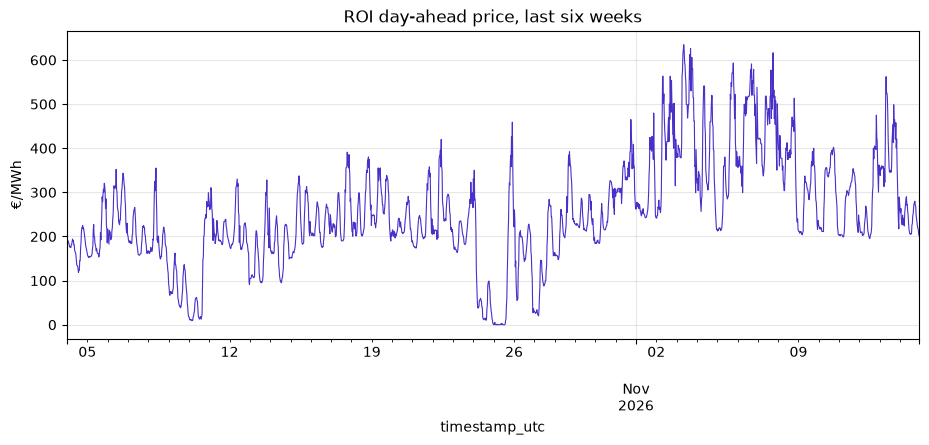

In [2]:
recent = prices[prices.index >= prices.index.max() - pd.Timedelta(days=42)]
ax = recent.tz_convert("Europe/Dublin").plot(lw=0.8, color="#4b2fc9")
ax.set_ylabel("€/MWh")
ax.set_title("ROI day-ahead price, last six weeks")
plt.show()

## Load the model

`device` picks the Mac's graphics chip (`mps`) when there is one, otherwise the CPU. Both work; the chip is a few times faster.

In [3]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
model = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=device)
print("running on", device)

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

running on mps


## One forecast

`forecast_day` is the whole method. It takes the price history and the half-hours to forecast, keeps the last `context_days` days of history, and asks Chronos-2 for the 10%, 50% and 90% quantiles.

Chronos-2 wants a table with three columns: which series (`item_id`), when (`timestamp`) and the value (`target`). It wants plain timestamps without a time zone, so UTC is dropped just for the call; the series stays evenly spaced every 30 minutes, which is what matters.

In [4]:
QUANTILES = [0.1, 0.5, 0.9]


def forecast_day(history, targets, context_days=28):
    # The 10%, 50% and 90% forecasts for each target half-hour,
    # from the last `context_days` days of history.
    recent = history[-context_days * 48 :]
    table = pd.DataFrame(
        {"item_id": "ROI", "timestamp": recent.index.tz_convert(None), "target": recent.values}
    )
    answer = model.predict_df(table, prediction_length=len(targets), quantile_levels=QUANTILES)
    return pd.DataFrame(
        {"low": answer["0.1"].values, "median": answer["0.5"].values, "high": answer["0.9"].values},
        index=targets,
    )


days = delivery_day(prices.index)
latest = max(days)
targets = prices.index[days == latest]
history = prices[prices.index < targets[0]]  # only what was known before the day
one = forecast_day(history, targets)
one["actual"] = prices[targets]
one.head()

,low,median,high,actual
timestamp_utc,,,,
2026-11-13 23:00:00+00:00,209.3,225.1,251.4,289.4
2026-11-13 23:30:00+00:00,196.8,213.3,238.5,276.3
2026-11-14 00:00:00+00:00,193.0,210.8,239.8,261.1
2026-11-14 00:30:00+00:00,187.9,207.4,239.6,254.1
2026-11-14 01:00:00+00:00,187.6,210.7,259.5,263.4


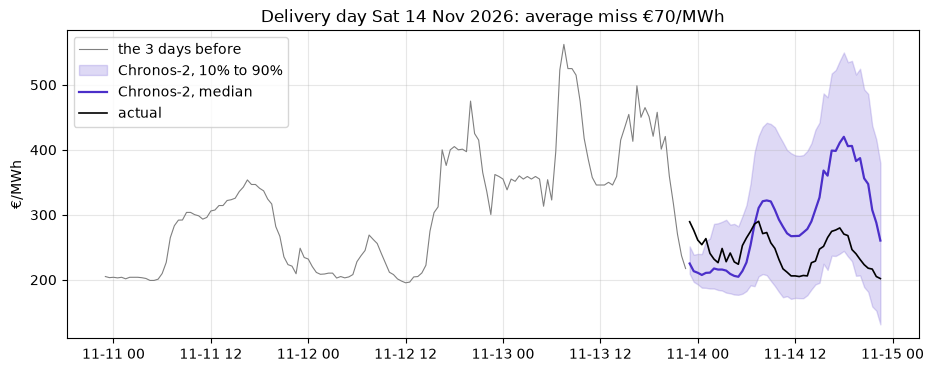

In [5]:
def plot_day(day, context_days=28, ax=None):
    # The forecast for one delivery day, its 80% range, the actual price and the 3 days before.
    targets = prices.index[days == day]
    history = prices[prices.index < targets[0]]
    f = forecast_day(history, targets, context_days)
    ax = ax or plt.gca()
    before = history[-3 * 48 :].tz_convert("Europe/Dublin")
    t = targets.tz_convert("Europe/Dublin")
    ax.plot(before.index, before.values, color="grey", lw=0.8, label="the 3 days before")
    band = "Chronos-2, 10% to 90%"
    ax.fill_between(t, f["low"], f["high"], color="#4b2fc9", alpha=0.18, label=band)
    ax.plot(t, f["median"], color="#4b2fc9", lw=1.6, label="Chronos-2, median")
    ax.plot(t, prices[targets].values, color="black", lw=1.2, label="actual")
    miss = (f["median"] - prices[targets]).abs().mean()
    ax.set_title(f"Delivery day {day:%a %d %b %Y}: average miss €{miss:.0f}/MWh")
    ax.set_ylabel("€/MWh")
    return ax


plot_day(latest)
plt.legend(loc="upper left")
plt.show()

## A whole year, day by day

The same test as the baselines (see `evaluate.py`): for every delivery day, Chronos-2 sees only the prices from before that day, forecasts the day, and is scored against what happened. Every method is scored on the same half-hours.

It also tries three lengths of history (7, 28 and 90 days), to see how much the model gains from looking further back. A whole year takes about 15 to 20 seconds per setting on an M1 Pro.

In [6]:
start, end = min(days) + timedelta(days=7), max(days)  # a week in, as for the baselines
ranges = {}  # each setting's 10%-90% range, kept for the range check below


def chronos(context_days):
    # A forecaster in the shape walk_forward expects: (history, targets) -> one price per target.
    def forecaster(history, targets):
        f = forecast_day(history, targets, context_days)
        ranges.setdefault(context_days, []).append(f[["low", "high"]])
        return f["median"]

    return forecaster


results = {name: walk_forward(prices, method, start, end) for name, method in BASELINES.items()}
for context_days in [7, 28, 90]:
    results[f"chronos2_{context_days}d"] = walk_forward(prices, chronos(context_days), start, end)

scored = len(errors(results))
print(f"Delivery days {start} to {end}: {scored:,} half-hours, the same for every method")
summary(results)

Delivery days 2025-11-14 to 2026-11-14: 17,566 half-hours, the same for every method


,MAE,RMSE
chronos2_90d,28.4,43.7
chronos2_28d,28.7,44.4
chronos2_7d,30.9,46.5
week_average,37.5,54.3
yesterday,41.1,60.4
last_week,49.4,74.2


**How to read this:** MAE is the average size of the miss in €/MWh; RMSE is similar but punishes big misses more. Lower is better. `week_average` is the best simple method, the bar to beat.

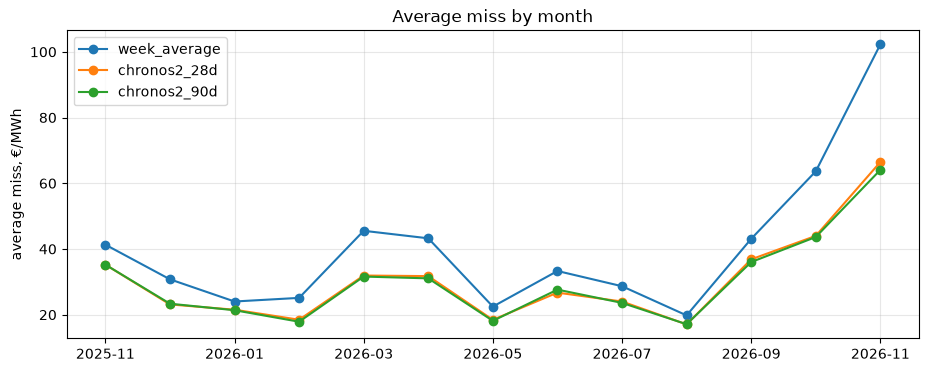

,yesterday,last_week,week_average,chronos2_7d,chronos2_28d,chronos2_90d
2025-11,52.5,48.1,41.3,44.0,35.2,35.2
2025-12,35.2,39.9,30.8,26.4,23.1,23.3
2026-01,26.6,33.3,24.0,23.9,21.5,21.4
2026-02,23.3,29.4,25.1,18.3,18.5,17.9
2026-03,49.7,65.5,45.5,37.4,31.9,31.6
2026-04,50.9,53.2,43.2,31.7,31.7,31.1
2026-05,25.1,34.5,22.5,18.8,18.4,18.1
2026-06,38.3,40.7,33.3,30.7,26.7,27.6
2026-07,34.1,32.4,28.7,27.4,24.0,23.6
2026-08,21.6,27.0,19.8,20.3,17.0,17.1


In [7]:
monthly = mae_by_month(results)
monthly[["week_average", "chronos2_28d", "chronos2_90d"]].plot(marker="o")
plt.ylabel("average miss, €/MWh")
plt.title("Average miss by month")
plt.show()
monthly

## Is the 80% range honest?

If the 10% and 90% forecasts are right, the actual price should land between them 80% of the time. Much less means the model is overconfident (its ranges are too narrow); much more means it's too cautious.

In [8]:
rows = []
for context_days, parts in ranges.items():
    band = pd.concat(parts)
    actual = prices[band.index]
    inside = ((actual >= band["low"]) & (actual <= band["high"])).mean()
    rows.append(
        {
            "history": f"{context_days} days",
            "inside the range": f"{inside:.0%}",
            "average width (€/MWh)": round((band["high"] - band["low"]).mean(), 1),
        }
    )
pd.DataFrame(rows)

,history,inside the range,average width (€/MWh)
0,7 days,70%,83.5
1,28 days,72%,79.4
2,90 days,74%,80.7


## Its best and worst days

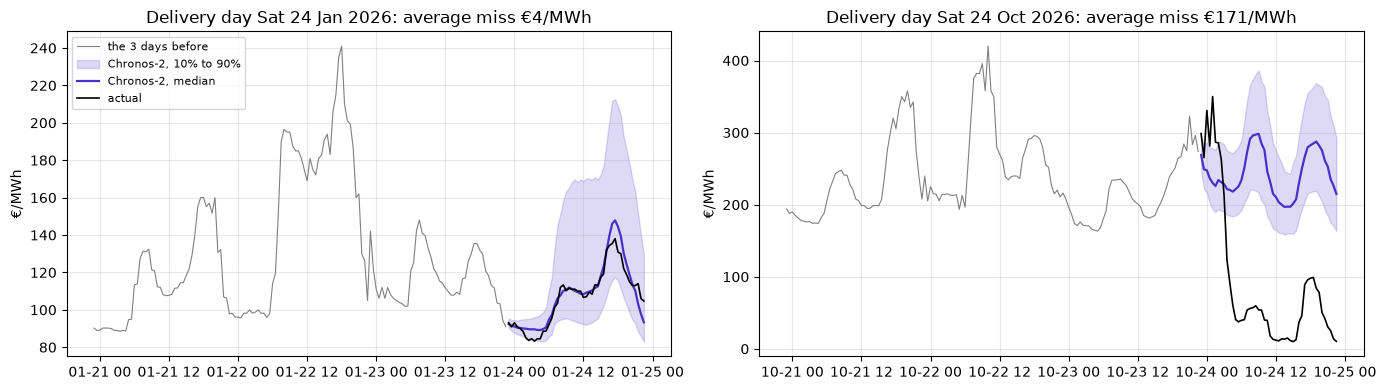

In [9]:
miss = (results["chronos2_28d"]["forecast"] - results["chronos2_28d"]["actual"]).abs()
by_day = miss.groupby(results["chronos2_28d"]["delivery_day"]).mean()
best, worst = by_day.idxmin(), by_day.idxmax()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_day(best, ax=axes[0])
plot_day(worst, ax=axes[1])
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## What this shows

Fill these in from your own run; the numbers below are from the first run on 15 Nov 2026, with prices up to 14 Nov:

- **Chronos-2 beats every simple method, with no training at all.** With 28 to 90 days of history, its average miss was about €28/MWh against €37.5 for `week_average`: about a quarter lower. With 28 days or more of history, it was ahead in every one of the 13 months.
- **A month of history is enough.** 28, 90 and 170 days score almost the same; 7 days is clearly worse. The daily and weekly rhythm is what it uses.
- **Its range is a little overconfident.** The 80% range held the real price about 73% of the time. Fixable later, for example with conformal prediction, which widens the range until it's honest.
- **It struggles where the price jumps for reasons outside the price history:** October and November 2026, when wind and gas moved prices fast. That's exactly what the next step tries to fix.

This differs from the 2025 European study in the wiki (Hornek et al.), where foundation models only matched good statistical methods. Here the comparison is with simple baselines, not with a tuned statistical model. The fair next comparison is a proper model (LEAR or LightGBM), on the same days.

## Next: give it the wind forecast

Chronos-2 can take *known future* series: values you already have for tomorrow when you forecast, like EirGrid's wind forecast. The trap: `isem-data` stores the *latest* revision of EirGrid's wind forecast, not the one known at 11:00 the day before the auction. Using it would let the model peek at information a trader didn't have. The honest version uses the per-farm forecasts `isem-data` has kept, every version, since August 2026.

## Things to try

- Change `context_days` in `plot_day(latest, context_days=...)` and see how the forecast changes.
- Ask for wider quantiles, e.g. `QUANTILES = [0.05, 0.5, 0.95]`.
- Forecast Northern Ireland: `load_prices(region="NI")` (the price is the same; the volumes differ).
- Pick a day you remember was strange and plot it: `plot_day(pd.Timestamp("2026-10-20").date())`.